# Mapping replication features with `rmap`

A guided atlas of deterministic predictions and inverse fits. Start with a known synthetic replication programme so that each output can be checked against its input assumptions; the [quickstart](0-quickstart.ipynb) covers experimental timing data.

Run all cells in order with DNAscape installed. No network access is needed. Outputs go to `examples/outputs/mapping/`.

1. Routes, shapes and units
2. Forward maps across kinetic dependences
3. Fit initiation rate
4. Fit fork speed
5. Directionality, fork density and event densities
6. Export a reproducible result


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "mapping"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import rmap, rsave, plotf
from dnascape.workflows import mapping_routes

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\mapping


## 1. Routes, shapes and units

`source` holds observed profiles or supplied kinetic quantities; `target` names the requested feature. `assumptions` records resolution, geometry, dependence and fitting controls. A scalar is constant, `(n,)` is spatial, `(1, T)` is temporal, and `(n, T)` is space–time.

In the direct Python `rmap` API, initiation rate is **kb⁻¹ min⁻¹** and fork speed **kb/min**. Convert an initiation-rate density to a per-bin rate by multiplying by the bin width before calling `rsim`. The app performs this conversion at its workflow boundary.

`rmap.targets()` lists features; `rmap.requirements(target="fork_speed")` describes the available routes and assumptions. Below is a compact catalogue of the routes exposed by the Mapping workflow.


In [2]:
routes = mapping_routes()
route_table = pd.DataFrame(
    [
        {
            "Target": route.target,
            "Dependence": route.output_dependence,
            "Method": route.method,
        }
        for route in routes
    ]
)
route_table.groupby("Target", sort=False).size().rename("Available routes").to_frame()


,Available routes
Target,
replication_timing,5
initiation_rate,11
fork_speed,11
fork_directionality,6
replicated_fraction_xt,3
replicated_fraction,2
initiation_events_xt,2
initiation_events,3
origin_efficiency,4


### A small reference model

The spatial coordinate starts at zero; add an experimental region offset only when plotting or exporting. Both axes are explicit. The horizon is long enough for the reference replicated fraction to approach one.


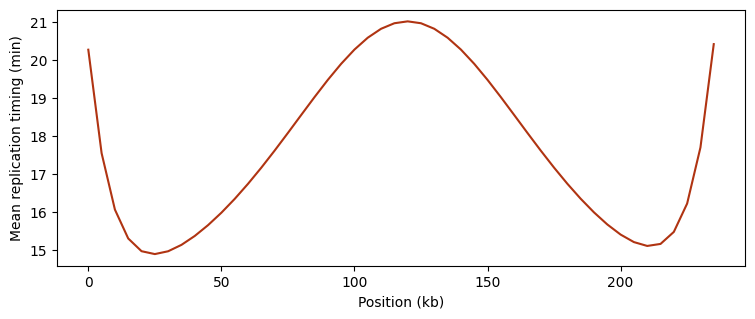

In [3]:
DX_KB = 5.0
DT_MIN = 5.0
N_BINS = 48
positions_kb = np.arange(N_BINS) * DX_KB
time_min = np.arange(0.0, 201.0, DT_MIN)
ir_x = 0.002 * (1.0 + 0.4 * np.cos(2 * np.pi * positions_kb / (N_BINS * DX_KB)))
v0 = 1.4
forward_options = {
    "resolution_x": DX_KB,
    "resolution_t": DT_MIN,
    "time_grid": time_min,
    "n_bins": N_BINS,
    "verbose": False,
}
reference_fraction = rmap(
    {"initiation_rate": ir_x, "fork_speed": v0},
    "replicated_fraction_xt",
    assumptions=forward_options,
)
observed_timing = np.trapezoid(1.0 - reference_fraction, time_min, axis=1)
assert reference_fraction.shape == (N_BINS, time_min.size)
assert np.min(reference_fraction[:, -1]) > 0.999
plotf(
    observed_timing,
    x_array=positions_kb,
    xtitle="Position (kb)",
    ytitle="Mean replication timing (min)",
    figsize=(8, 3.2),
)


## 2. Forward maps across kinetic dependences

All four input shapes work for initiation rate and fork speed. These examples produce replicated-fraction fields on the same region and time grid. They illustrate input conventions rather than asserting that the models are biologically equivalent.


In [4]:
ir_inputs = {
    "constant": 0.002,
    "space": ir_x,
    "time": (0.001 * (1.0 + time_min / 40.0))[None, :],
    "spacetime": ir_x[:, None] * (1.0 + time_min[None, :] / 80.0),
}
speed_inputs = {
    "constant": v0,
    "space": 1.1 + 0.3 * np.sin(positions_kb / 60.0) ** 2,
    "time": (1.0 + 0.5 * time_min / 100.0)[None, :],
    "spacetime": (1.1 + 0.2 * np.sin(positions_kb / 60.0))[:, None]
    * (1.0 + time_min[None, :] / 200.0),
}
forward_fields = {}
for form in ir_inputs:
    field = rmap(
        {"initiation_rate": ir_inputs[form], "fork_speed": speed_inputs[form]},
        "replicated_fraction_xt",
        assumptions=forward_options,
    )
    assert field.shape == (N_BINS, time_min.size) and np.isfinite(field).all()
    assert np.all(np.diff(field, axis=1) >= -1e-9)
    forward_fields[form] = field
pd.DataFrame(
    {
        "Dependence": list(forward_fields),
        "Final replicated fraction": [f[:, -1].mean() for f in forward_fields.values()],
    }
)


,Dependence,Final replicated fraction
0,constant,1.0
1,space,1.0
2,time,1.0
3,spacetime,1.0


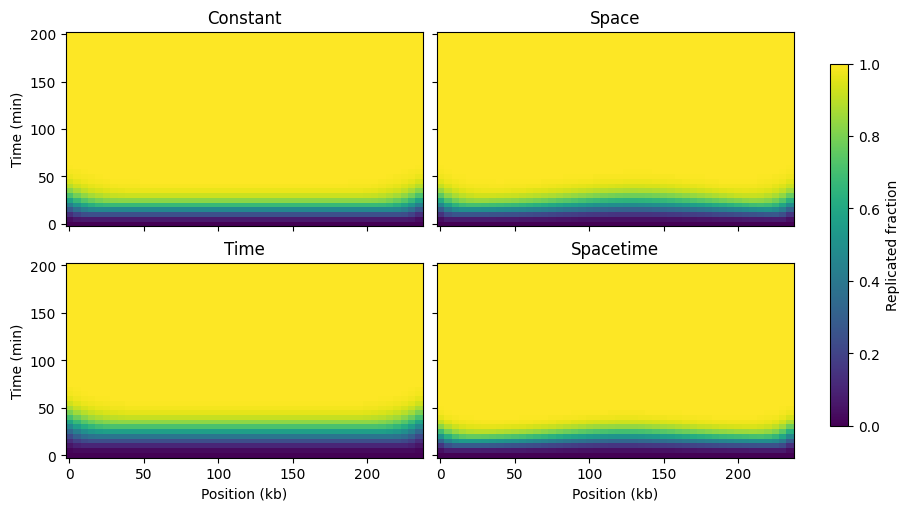

In [5]:
fig, axes = plt.subplots(
    2, 2, figsize=(9, 5), sharex=True, sharey=True, layout="constrained"
)
for ax, (form, field) in zip(axes.flat, forward_fields.items()):
    image = ax.pcolormesh(
        positions_kb, time_min, field.T, shading="auto", vmin=0, vmax=1
    )
    ax.set(title=form.title(), xlabel="Position (kb)", ylabel="Time (min)")
    ax.label_outer()
fig.colorbar(image, ax=list(axes.flat), label="Replicated fraction", shrink=0.85)
plt.show()


### Mean timing from a progression field

Mean timing is the time integral of the unreplicated fraction. A finite horizon must capture the survival tail. The dedicated timing route is convenient for spatial kinetics and chooses its integration settings internally.


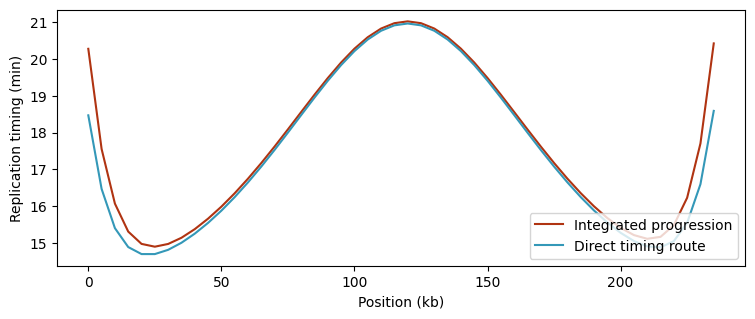

Difference between discretisations: MSE 0.226 min²


In [6]:
mapped_timing = rmap(
    {"initiation_rate": ir_x, "fork_speed": v0},
    "replication_timing",
    assumptions={"resolution_x": DX_KB, "verbose": False},
)
plotf(
    observed_timing,
    mapped_timing,
    x_array=positions_kb,
    labels=["Integrated progression", "Direct timing route"],
    xtitle="Position (kb)",
    ytitle="Replication timing (min)",
    figsize=(8, 3.2),
)
print(
    f"Difference between discretisations: MSE {np.mean((mapped_timing-observed_timing)**2):.4g} min²"
)


## 3. Fit initiation rate

Choose `target_form` explicitly. Constant and spatial examples infer time-independent rates. Temporal and space–time examples below use a Weibull hazard,

$$I(x,t)=k\,\alpha(x)\,\max(t-d,0)^{k-1}.$$

Here `k=2` and `d=0`; the fitted amplitude has different units from the instantaneous rate, and `k=1` recovers a time-independent hazard. These target assumptions differ, so fitting the same timing profile does not imply recovery of the same initiation programme.


In [7]:
initiation_fits = {}
records = []
for form in ("constant", "space", "time", "spacetime"):
    options = {
        **forward_options,
        "target_form": form,
        "maxiter": 6,
        "temporal_maxiter": 6,
        "refine_edge_kb": 0.0,
    }
    if form in {"time", "spacetime"}:
        options.update(target_shape="weibull", weibull_shape=2.0, weibull_delay=0.0)
    result = rmap(
        {"replication_timing": observed_timing, "fork_speed": v0},
        "initiation_rate",
        assumptions=options,
        return_info=True,
    )
    values = np.asarray(result["values"])
    predicted_fraction = rmap(
        {"initiation_rate": values, "fork_speed": v0},
        "replicated_fraction_xt",
        assumptions=forward_options,
    )
    predicted = np.trapezoid(1.0 - predicted_fraction, time_min, axis=1)
    initiation_fits[form] = result
    records.append(
        {
            "Target dependence": form,
            "Shape": values.shape,
            "Timing MSE (min²)": np.mean((predicted - observed_timing) ** 2),
        }
    )
pd.DataFrame(records)


,Target dependence,Shape,Timing MSE (min²)
0,constant,(),6.540998831912748
1,space,"(48,)",0.10504394136240419
2,time,"(1, 41)",4.646785538262404
3,spacetime,"(48, 41)",0.028101646942083367


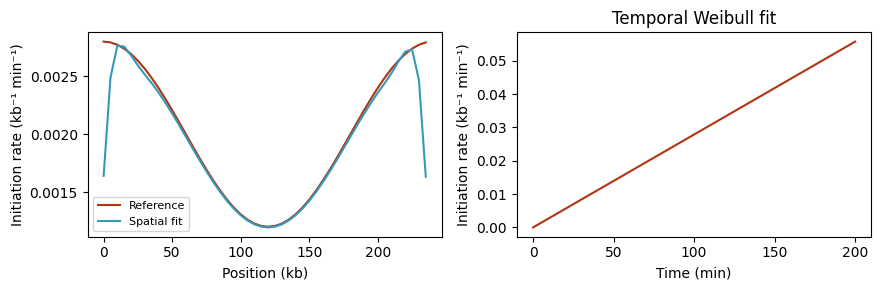

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(positions_kb, ir_x, label="Reference")
axes[0].plot(positions_kb, initiation_fits["space"]["values"], label="Spatial fit")
axes[0].set(xlabel="Position (kb)", ylabel="Initiation rate (kb⁻¹ min⁻¹)")
axes[0].legend(fontsize=8)
axes[1].plot(time_min, np.asarray(initiation_fits["time"]["values"]).reshape(-1))
axes[1].set(
    xlabel="Time (min)",
    ylabel="Initiation rate (kb⁻¹ min⁻¹)",
    title="Temporal Weibull fit",
)
fig.tight_layout()
plt.show()


### Bounds and the initial guess

Use bounds for the fitted quantity; supplied timing stays unchanged. This spatial fit starts at an explicit rate density and keeps the returned rate within the selected limits. Bounds on Weibull targets constrain their fitted amplitudes, not every instantaneous rate value.


In [9]:
bounded_ir = rmap(
    {"replication_timing": observed_timing, "fork_speed": v0},
    "initiation_rate",
    assumptions={
        "target_form": "space",
        "resolution_x": DX_KB,
        "maxiter": 4,
        "initial_initiation_rate": 0.002,
        "rate_bounds": (1e-5, 0.01),
        "refine_edge_kb": 0.0,
        "verbose": False,
    },
)
assert np.all((bounded_ir >= 1e-5) & (bounded_ir <= 0.01))
print(f"Fitted rate range: {bounded_ir.min():.4g}–{bounded_ir.max():.4g} kb⁻¹ min⁻¹")


Fitted rate range: 0.001195–0.002695 kb⁻¹ min⁻¹


## 4. Fit fork speed

Infer fork speed from timing and a supplied initiation rate. Time-only and space–time fits have separate temporal controls; space–time fits also expose the spatial iteration budget and component order. The small budgets here keep the tutorial responsive. Increase them and compare the final forward prediction when analysing real data.

A timing curve alone does not uniquely determine a general speed field. These examples hold initiation fixed and use constrained target families.


In [10]:
speed_fits = {}
records = []
for form in ("constant", "space", "time", "spacetime"):
    fit_options = {
        **forward_options,
        "target_form": form,
        "refine_edge_kb": 0.0,
        "smoothw": None,
        "speed_bounds": (0.2, 6.0),
        "initial_fork_speed": 1.4,
    }
    if form == "spacetime":
        fit_options.update(
            space_maxiter=3, temporal_maxiter=4, spacetime_order="time_then_space"
        )
    elif form == "time":
        fit_options["temporal_maxiter"] = 4
    else:
        fit_options["maxiter"] = 4
    info = rmap(
        {"replication_timing": observed_timing, "initiation_rate": ir_x},
        "fork_speed",
        assumptions=fit_options,
        return_info=True,
    )
    values = np.asarray(info["values"])
    assert np.isfinite(values).all() and np.all((values >= 0.2) & (values <= 6.0))
    fitted_fraction = rmap(
        {"initiation_rate": ir_x, "fork_speed": values},
        "replicated_fraction_xt",
        assumptions=forward_options,
    )
    fitted_timing = np.trapezoid(1.0 - fitted_fraction, time_min, axis=1)
    speed_fits[form] = info
    records.append(
        {
            "Target dependence": form,
            "Shape": values.shape,
            "Timing MSE (min²)": np.mean((fitted_timing - observed_timing) ** 2),
        }
    )
pd.DataFrame(records)


,Target dependence,Shape,Timing MSE (min²)
0,constant,(),0.8050742142021976
1,space,"(48,)",0.029682261521801163
2,time,"(1, 41)",0.0004832235524325714
3,spacetime,"(48, 41)",0.00036573612717827157


### A genuinely varying temporal speed

Generate a timing observation from a growing speed profile, then fit `v(t)` with a known spatial initiation input. Plot time-dependent quantities against **time**, not genomic position. Compare timing predictions as well as speed curves; weakly observed late-time values may remain poorly constrained.


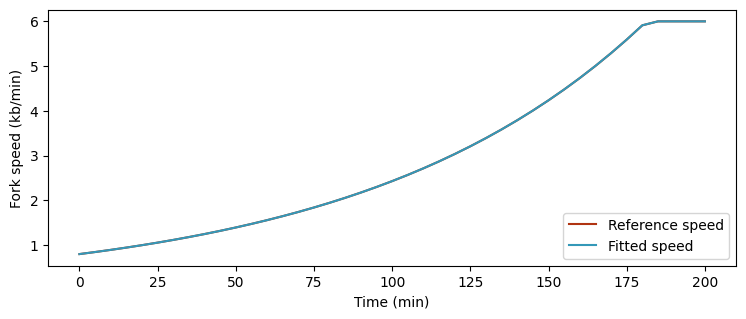

Timing-fit MSE: 4.8878e-10 min²


In [11]:
truth_vt = np.minimum(0.8 * np.exp(time_min / 90.0), 6.0)[None, :]
truth_fraction = rmap(
    {"initiation_rate": ir_x, "fork_speed": truth_vt},
    "replicated_fraction_xt",
    assumptions=forward_options,
)
temporal_observation = np.trapezoid(1.0 - truth_fraction, time_min, axis=1)
time_speed_fit = rmap(
    {"replication_timing": temporal_observation, "initiation_rate": ir_x},
    "fork_speed",
    assumptions={
        **forward_options,
        "target_form": "time",
        "temporal_maxiter": 10,
        "refine_edge_kb": 0.0,
        "speed_bounds": (0.2, 6.0),
    },
    return_info=True,
)
fitted_time = np.asarray(time_speed_fit["time_grid"])
fitted_vt = np.asarray(time_speed_fit["values"]).reshape(-1)
plotf(
    truth_vt.reshape(-1),
    fitted_vt,
    x_array=fitted_time,
    labels=["Reference speed", "Fitted speed"],
    xtitle="Time (min)",
    ytitle="Fork speed (kb/min)",
    figsize=(8, 3.2),
)
print(f"Timing-fit MSE: {time_speed_fit['fit_mse']:.5g} min²")


## 5. Directionality, fork density and event densities

For constant fork speed, the timing gradient gives a spatial directionality profile. A supplied speed and initiation profile can also be mapped to timing and then directionality. Use `rsim` when you want stochastic origin efficiencies or distributions across individual S phases.


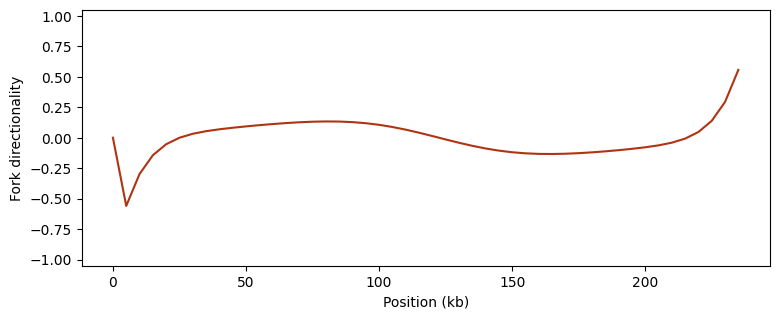

In [12]:
directionality = rmap(
    {"replication_timing": mapped_timing, "fork_speed": v0},
    "fork_directionality",
    assumptions={"resolution_x": DX_KB, "verbose": False},
)
assert np.max(np.abs(directionality)) <= 1.0 + 1e-9
plotf(
    directionality,
    x_array=positions_kb,
    xtitle="Position (kb)",
    ytitle="Fork directionality",
    limsy=(-1.05, 1.05),
    figsize=(8, 3.2),
)


### Directional and total fork densities

The mean-field density bundle returns right-moving, left-moving and total fork densities on the same space–time grid. Densities count forks per genomic length; they are not probability densities normalised to integrate to one.


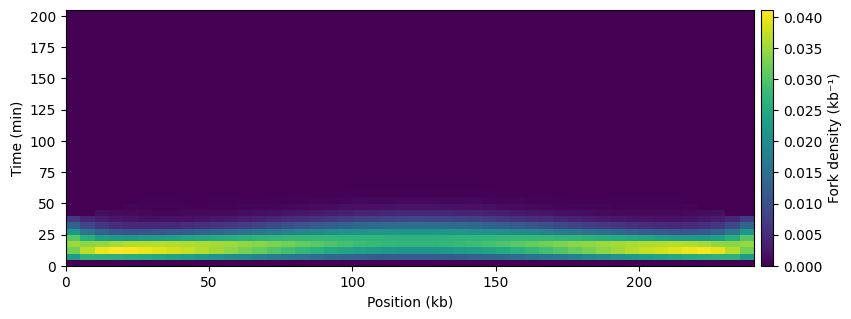

In [13]:
kinetic_source = {"initiation_rate": ir_x, "fork_speed": v0}
fork_fields = rmap(kinetic_source, "fork_densities_xt", assumptions=forward_options)
np.testing.assert_allclose(
    fork_fields["fork_density_xt"],
    fork_fields["right_fork_density_xt"] + fork_fields["left_fork_density_xt"],
)
plotf(
    fork_fields["fork_density_xt"],
    x_array=positions_kb,
    time_array=time_min,
    xtitle="Position (kb)",
    ytitle="Time (min)",
    labels=["Fork density (kb⁻¹)"],
    figsize=(8, 3.2),
)


### Initiation and coalescence event densities

Actual initiation density is potential initiation rate multiplied by the unreplicated fraction. Coalescence density describes encounters between opposing forks. These fields have units **events/(kb min)**; their time integrals are spatial event densities in **events/kb**, not normalised probabilities.


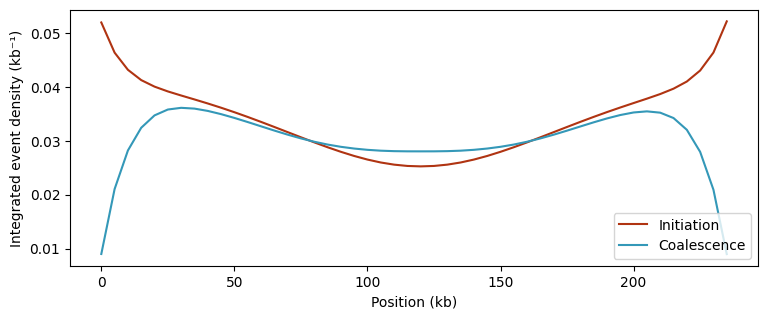

In [14]:
initiation_events = rmap(
    kinetic_source, "initiation_events_xt", assumptions=forward_options
)
coalescence_events = rmap(
    kinetic_source, "coalescence_events_xt", assumptions=forward_options
)
assert initiation_events.shape == coalescence_events.shape == reference_fraction.shape
spatial_event_density = pd.DataFrame(
    {
        "position_kb": positions_kb,
        "initiation_events_per_kb": np.trapezoid(initiation_events, time_min, axis=1),
        "coalescence_events_per_kb": np.trapezoid(coalescence_events, time_min, axis=1),
    }
)
plotf(
    spatial_event_density["initiation_events_per_kb"],
    spatial_event_density["coalescence_events_per_kb"],
    x_array=positions_kb,
    labels=["Initiation", "Coalescence"],
    xtitle="Position (kb)",
    ytitle="Integrated event density (kb⁻¹)",
    figsize=(8, 3.2),
)


## 6. Export a reproducible result

Use `_c`, `_x`, `_t` and `_xt` to distinguish constant, space, time and space–time results. Store explicit axes and units with matrices. Here NPZ keeps the full numerical fields, and TSV keeps the compact spatial summary.


In [15]:
np.savez_compressed(
    OUTPUT_DIR / "mapping_xt.npz",
    positions_kb=positions_kb,
    time_min=time_min,
    resolution_kb=DX_KB,
    initiation_rate_per_kb_min=ir_x,
    fork_speed_kb_min=v0,
    replicated_fraction_xt=reference_fraction,
    fork_density_per_kb_xt=fork_fields["fork_density_xt"],
    initiation_events_per_kb_min_xt=initiation_events,
    coalescence_events_per_kb_min_xt=coalescence_events,
)
rsave(spatial_event_density, OUTPUT_DIR / "event_density_x.tsv")
print("Saved mapping_xt.npz and event_density_x.tsv")


Saved mapping_xt.npz and event_density_x.tsv


Next: [stochastic simulation and optional mechanisms](3-simulation.ipynb). See [worked studies](4-neat_examples.ipynb) for masked perturbations and comparisons, and [plotting](5-plotting.ipynb) for static and interactive figures. API signatures and route requirements remain available in the [mapping documentation](https://dnascape.readthedocs.io/en/latest/mappingfunctions.html).
